## 02 - Baselines 

### (Specifications 2 & 3)

1. **Single agent**: direct answer vs. answer with a short justification (temperature 0).
2. **Independent multi-agent answering**: 3 calls that never see each other's output (temperature > 0), majority vote
   with a reproducible tie-break (hash method was used). and the same model for every call.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data_loader, metrics, prompts
config.ensure_dirs()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SPLIT = "test"   #"dev" for development (100 questions from validation split); "test" for the testing (300 questions from test split)
print("model:", config.MODEL, "| server:", config.BASE_URL)

model: llama3.1:8b | server: http://localhost:11434/v1


In [2]:
from src.debate_engine import run_dataset, run_single, run_independent, transcript_path, load_records
from src.llm_client import LLMClient

client = LLMClient()
questions = data_loader.load_sampled(SPLIT)
qids = [q.id for q in questions]
print(len(questions), "questions; split =", SPLIT)

300 questions; split = test


### Specification 2 - single-agent baselines (Direct Vs with Justification)

In [3]:
single = {}
for mode in ("direct", "justify"):
    recs = run_dataset(lambda q, m=mode: run_single(client, q, m), questions, transcript_path(SPLIT, f"single_{mode}"))
    single[mode] = {r["qid"]: r for r in recs}
print(client.stats)

r = single["justify"][qids[0]]
{k: r["calls"][0][k] for k in ("answer", "text", "model", "temperature", "input_tokens", "output_tokens", "latency_s", "stop_reason", "cached")}

test_single_direct: 0it [00:00, ?it/s]

test_single_justify: 0it [00:00, ?it/s]

{'calls': 0, 'cached_calls': 0, 'input_tokens': 0, 'output_tokens': 0}


{'answer': 'D',
 'text': 'Cutting down trees to build new homes (option C) would have a negative effect on the natural environment because it would lead to deforestation, loss of biodiversity, and increased greenhouse gas emissions. Building dams to produce electricity (option B) can also have negative effects, such as disrupting natural water flows and affecting aquatic ecosystems. Using natural gas to heat homes (option A) is a fossil fuel that contributes to climate change. Recycling paper to reduce the cutting of trees (option D) is a sustainable practice that conserves natural resources and reduces waste.\n\nAnswer: D',
 'model': 'llama3.1:8b',
 'temperature': 0.0,
 'input_tokens': 137,
 'output_tokens': 114,
 'latency_s': 4.812711900100112,
 'stop_reason': 'stop',
 'cached': False}

### Specification 3 - independent multi-agent answering + majority vote

In [4]:
ind_recs = run_dataset(lambda q: run_independent(client, q, config.MAX_INDEP_SAMPLES, "justify"),
                       questions, transcript_path(SPLIT, "independent_justify"))
ind = {r["qid"]: r for r in ind_recs}
ind_direct_recs = run_dataset(lambda q: run_independent(client, q, config.N_AGENTS, "direct"),
                              questions, transcript_path(SPLIT, "independent_direct"))
ind_direct = {r["qid"]: r for r in ind_direct_recs}
print(client.stats)

test_independent_justify: 0it [00:00, ?it/s]

test_independent_direct: 0it [00:00, ?it/s]

{'calls': 0, 'cached_calls': 0, 'input_tokens': 0, 'output_tokens': 0}


### Comparisons

In [5]:
def corr(recs, getter):
    return np.array([metrics.is_correct(getter(recs[i]), recs[i]["gold"]) for i in qids])

def row(name, correct, usage_list, extra=None):
    mean, lo, hi = metrics.bootstrap_ci(correct)
    d = {"method": name, "accuracy": mean,
         "tokens/question": np.mean([u["total_tokens"] for u in usage_list]),
         "latency": np.mean([u["latency_critical_s"] for u in usage_list])}
    d.update(extra or {}); return d

N = config.N_AGENTS
c_direct = corr(single["direct"], lambda r: r["answer"])
c_just = corr(single["justify"], lambda r: r["answer"])
c_vote = corr(ind, lambda r: metrics.vote_at_k(r, N)["answer"])
c_vote_direct = corr(ind_direct, lambda r: metrics.majority_vote(r["answers"], r["qid"])["answer"])

parse_fail = lambda recs, n=None: np.mean([c["answer"] is None for i in qids for c in recs[i]["calls"][:n]])
rows = [
    row("single: direct (T=0)", c_direct, [metrics.usage(single["direct"][i]["calls"]) for i in qids], {"unparsed": parse_fail(single["direct"])}),
    row("single: + justification (T=0)", c_just, [metrics.usage(single["justify"][i]["calls"]) for i in qids], {"unparsed": parse_fail(single["justify"])}),
    row(f"independent x{N} direct, majority", c_vote_direct, [metrics.usage(ind_direct[i]["calls"]) for i in qids], {"unparsed": parse_fail(ind_direct)}),
    row(f"independent x{N} justified, majority", c_vote, [metrics.usage(ind[i]["calls"], agents=range(N)) for i in qids], {"unparsed": parse_fail(ind, N)}),
]
baseline = pd.DataFrame(rows).round(4)
baseline.to_csv(config.TABLES_DIR / f"{SPLIT}_baselines.csv", index=False)
baseline

,method,accuracy,tokens/question,latency,unparsed
0,single: direct (T=0),0.8033,131.6200,0.2846,0.0
1,single: + justification (T=0),0.8267,232.3000,4.0906,0.0
2,"independent x3 direct, majority",0.7967,394.8033,0.4022,0.0
3,"independent x3 justified, majority",0.8300,694.2133,8.0553,0.0


### McNemar's test on Agents & Sensitivity check on different tie-breaking rule

In [6]:
print("direct vs justification:", metrics.mcnemar_exact(c_direct, c_just))
print("single justified vs majority of 3:", metrics.mcnemar_exact(c_just, c_vote))

# independent-sample diagnostics
first = lambda r: r["answers"][:N]
votes = [metrics.vote_at_k(ind[i], N) for i in qids]
print(f"\nvote ties (no strict plurality): {np.mean([v['tied'] for v in votes]):.1%} of questions")
print(f"mean single-sample accuracy (T=0.7): {np.mean([[metrics.is_correct(a, ind[i]['gold']) for a in first(ind[i])] for i in qids]):.3f}")
print(f"mean pairwise disagreement: {np.mean([metrics.pairwise_disagreement(first(ind[i])) for i in qids]):.3f}")
print(f"unanimous: {np.mean([metrics.is_unanimous(first(ind[i])) for i in qids]):.1%}")
print(f"oracle (any of {N} correct): {np.mean([any(metrics.is_correct(a, ind[i]['gold']) for a in first(ind[i])) for i in qids]):.3f}")

# tie-break sensitivity
for rule in ("hash", "first_agent", "lowest"):
    acc = np.mean([metrics.is_correct(metrics.majority_vote(first(ind[i]), i, rule)["answer"], ind[i]["gold"]) for i in qids])
    print(f"tie-break={rule:11s} majority accuracy {acc:.3f}")

direct vs justification: {'a_only': 16, 'b_only': 23, 'delta_acc_b_minus_a': 0.023333333333333317, 'p_value': 0.3367836351899314}
single justified vs majority of 3: {'a_only': 10, 'b_only': 11, 'delta_acc_b_minus_a': 0.0033333333333332993, 'p_value': 1.0}

vote ties (no strict plurality): 1.7% of questions
mean single-sample accuracy (T=0.7): 0.823
mean pairwise disagreement: 0.123
unanimous: 82.3%
oracle (any of 3 correct): 0.893
tie-break=hash        majority accuracy 0.830
tie-break=first_agent majority accuracy 0.837
tie-break=lowest      majority accuracy 0.823


### majority-vote accuracy by agent sample size (k = 1..9)

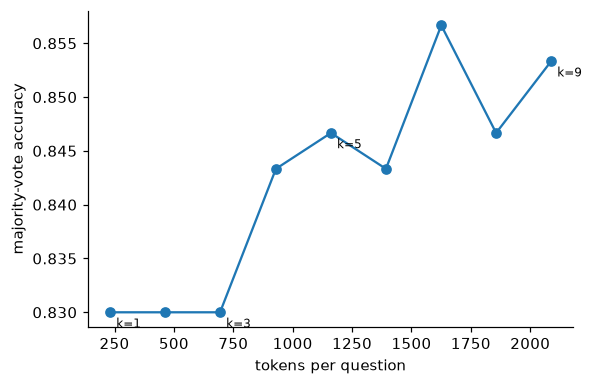

,k,accuracy,tokens/question
0,1,0.8300,231.5500
1,2,0.8300,463.2333
2,3,0.8300,694.2133
3,4,0.8433,929.4967
4,5,0.8467,1161.0400
5,6,0.8433,1392.5100
6,7,0.8567,1625.4833
7,8,0.8467,1856.3633
8,9,0.8533,2087.9900


In [7]:
# accuracy of majority vote vs number of independent samples (cumulative tokens on the x axis)
ks = list(range(1, config.MAX_INDEP_SAMPLES + 1))
acc_k = [np.mean([metrics.is_correct(metrics.vote_at_k(ind[i], k)["answer"], ind[i]["gold"]) for i in qids]) for k in ks]
tok_k = [np.mean([metrics.usage(ind[i]["calls"], agents=range(k))["total_tokens"] for i in qids]) for k in ks]
curve = pd.DataFrame({"k": ks, "accuracy": acc_k, "tokens/question": tok_k}).round(4)
curve.to_csv(config.TABLES_DIR / f"{SPLIT}_independent_vote_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(tok_k, acc_k, marker="o"); ax.set(xlabel="tokens per question", ylabel="majority-vote accuracy")
for k, x, y in zip(ks, tok_k, acc_k):
    if k in (1, 3, 5, 9, 15): ax.annotate(f"k={k}", (x, y), textcoords="offset points", xytext=(4, -10), fontsize=8)
plt.tight_layout(); plt.savefig(config.PLOTS_DIR / f"02_{SPLIT}_vote_vs_k.png"); plt.show()
curve